# LR-QAOA on the stabilizer Hamiltonian itself: X and Z checks together

The benchmark of `benchmark_codes_ibm.ipynb` turns every check of a code into a $Z \cdots Z$ term, so its
Hamiltonian is classical: all eight checks of the $d = 3$ surface code act in one basis (the $Z$ frame, or all in
$X$ in the $X$ frame). A real QEC round is different - half the checks are $X$-type and half $Z$-type, measured
together. This notebook asks whether the benchmark can use that exact pattern,

$$H = -\sum_{Z\ \text{checks}} Z_S \;-\; \sum_{X\ \text{checks}} X_S ,$$

and what happens to the mixer when the Hamiltonian is no longer diagonal.

**It can, and the mixer is not the obstacle.** The short version, each point checked below:

* the ground space of $H$ is the code space, so the LR-QAOA ramp is a digitised anneal *into the code*;
* with the usual $X$ mixer and the start $|+\rangle^{\otimes n}$, every $X$ check is satisfied from the first layer
  and stays satisfied, because the mixer and the $Z$ checks both commute with it. The ramp only has to bring the
  $Z$ checks to $+1$, and it ends in the logical state $|+\rangle_L$. With a $Z$ mixer from $|0\rangle^{\otimes n}$
  the roles swap and it ends in $|0\rangle_L$ - the two states of the two memory experiments;
* with a **$Y$ mixer** from $|{+i}\rangle^{\otimes n}$ nothing is conserved: $Y$ anticommutes with both kinds of
  check, all eight are driven, and the mixed Hamiltonian then gives *exactly* the numbers of the $Z$-only benchmark;
* the ancilla gadget the package already uses works for an $X \cdots X$ term as it does for a $Z \cdots Z$ one, so
  one layer measures all eight ancillas once, with the same number of CZ gates as today.

Everything here is simulation: nothing is submitted, and nothing in the package is changed. The circuit builder
lives in this notebook so the whole study can be removed by deleting one file.

In [2]:
import json
import sys
from functools import reduce
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))          # not needed after `pip install -e .`
DATA, FIGURES = ROOT / "data", ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister

from qecbench import codes
from qecbench import memory as mem
from qecbench.circuits import build_dynamic, compact_index, cz_rounds
from qecbench.lrqaoa import angles
from qecbench.primitives import CodePatch

## 1. Configuration - the only cell you normally edit

* `DELTA` - the slope of the linear ramp, as in the benchmark ($\gamma_k = k\Delta/p$, $\beta_k = (p-k+1)\Delta/p$).
* `EXACT_DEPTHS` - depths for the noiseless, exact evolution (cheap: nine data qubits).
* `SIM_DEPTHS`, `SHOTS`, `NOISE` - the gate-level simulation of section 7. It runs shot by shot and takes about
  20 minutes, so its result is kept in `data/stabilizer_study/comparison.json`; `RECOMPUTE = True` (or deleting
  that file) runs it again.

In [3]:
DELTA        = 0.5
EXACT_DEPTHS = [1, 2, 3, 5, 7, 10, 15, 20]
SIM_DEPTHS   = [1, 2, 3, 5, 7, 10]
SHOTS        = {"benchmark, Z frame": 400, "benchmark, X frame": 400,
                "stabilizer, to |+>_L": 600, "stabilizer, to |0>_L": 600, "stabilizer, Y mixer": 400}
NOISE        = {"cz": 0.003,            # depolarizing, per CZ
                "one_qubit": 0.0003,    # depolarizing, per single-qubit gate
                "readout": 0.01,        # every measurement, mid-circuit and final
                "idle_xy": 0.0025,      # the data while the ancillas are read: flips ...
                "idle_z": 0.0040}       # ... and dephasing
RECOMPUTE    = False
CACHE        = DATA / "stabilizer_study" / "comparison.json"

patch = CodePatch(codes.surface_code(3), kind="mcm")
n = patch.n_data
print(f"{patch.code.name}: {n} data qubits, {len(patch.terms)} checks, types {mem.check_types(patch.code)}")

surface_d3: 9 data qubits, 8 checks, types ('X', 'Z', 'Z', 'X', 'Z', 'X', 'X', 'Z')


## 2. The Hamiltonian, and why the mixer is not the problem

The checks of a stabilizer code commute with one another, so $H = -\sum_S S$ has a ground space in which every
check is $+1$: the code space. For the $d = 3$ surface code that space has dimension 2 (one logical qubit).

For a classical Hamiltonian the $X$ mixer works because it commutes with nothing in $H$. Here it commutes with
the $X$ checks - and that turns out to help rather than hurt. Starting from $|+\rangle^{\otimes n}$:

* every $X$ check has value $+1$ at the start, and nothing in the circuit can change it: the mixer is made of
  $X$'s, and the $Z$ checks commute with the $X$ checks because they are stabilizers of one code;
* the logical $X_L$ is $+1$ at the start and is conserved for the same reason;
* so the ramp acts only on the $Z$ checks, exactly as the benchmark does today, and where it succeeds the state
  is the unique state with all checks $+1$ and $X_L = +1$: the logical $|+\rangle_L$.

Swapping every role - a $Z$ mixer from $|0\rangle^{\otimes n}$ - conserves the $Z$ checks and $Z_L$ and anneals to
$|0\rangle_L$. The cell builds the operators and checks the claims that do not need an evolution.

In [4]:
I2, PX, PZ = np.eye(2), np.array([[0, 1], [1, 0.]]), np.diag([1., -1.])
PY = np.array([[0, -1j], [1j, 0]])
MIXER = {"X": PX, "Y": PY, "Z": PZ}                        # the three single-qubit mixers, and where each starts
START = {"X": np.ones(2) / np.sqrt(2), "Y": np.array([1, 1j]) / np.sqrt(2), "Z": np.array([1., 0.])}
position = {d: i for i, d in enumerate(patch.data_qubits)}


def pauli(op, support):
    # op on the data qubits in `support`, identity elsewhere; data qubit 0 is the most significant
    return reduce(np.kron, [op if i in support else I2 for i in range(n)])


code_types = mem.check_types(patch.code)
stabilizers = [pauli(PX if t == "X" else PZ, {position[d] for d in term.data})
               for term, t in zip(patch.terms, code_types)]
logical = {"X": pauli(PX, set(mem.logical_support(patch.code, "X"))),
           "Z": pauli(PZ, set(mem.logical_support(patch.code, "Z")))}
H_code = -sum(stabilizers)
code_space = reduce(np.matmul, [(np.eye(2 ** n) + s) / 2 for s in stabilizers])
plus_all = reduce(np.kron, [np.ones(2) / np.sqrt(2)] * n)

print("all checks commute with one another :", all(np.allclose(a @ b, b @ a) for a in stabilizers for b in stabilizers))
print("lowest energy of H                  :", round(float(np.linalg.eigvalsh(H_code)[0]), 6), f"(= -{len(stabilizers)})")
print("dimension of the ground space       :", round(float(np.trace(code_space))))
x_mixer = sum(pauli(PX, {i}) for i in range(n))
x_checks = [s for s, t in zip(stabilizers, code_types) if t == "X"]
print("X mixer commutes with every X check :", all(np.allclose(x_mixer @ s, s @ x_mixer) for s in x_checks))
print("X mixer commutes with X_L           :", np.allclose(x_mixer @ logical["X"], logical["X"] @ x_mixer))
print("|+>^n satisfies every X check       :", all(np.isclose(plus_all @ s @ plus_all, 1) for s in x_checks))

all checks commute with one another : True
lowest energy of H                  : -8.0 (= -8)
dimension of the ground space       : 2
X mixer commutes with every X check : True
X mixer commutes with X_L           : True
|+>^n satisfies every X check       : True


## 3. First test: the same ramp on the $Z$-only, the $X$-only and the mixed Hamiltonian

Before any circuit: build the three Hamiltonians on the same eight supports and run the same LR-QAOA ramp on
each, exactly.

* **$Z$-only** - every check a $Z \cdots Z$ term, $X$ mixer from $|+\rangle^{\otimes n}$: the benchmark's $Z$ frame.
* **$X$-only** - every check an $X \cdots X$ term, $Z$ mixer from $|0\rangle^{\otimes n}$: the benchmark's $X$ frame.
* **$Z$ and $X$** - each check in the basis the code gives it, $X$ mixer from $|+\rangle^{\otimes n}$.

The first two must agree, being one algorithm in two bases, and they do, check by check, and with the package's
own reference `ideal_r`. The third does **not** agree with them, although its Hamiltonian has exactly the same
spectrum: what differs is the relation to the mixer, which now commutes with half of the terms. And it is not a
new algorithm either - its driven checks follow, to machine precision, the ramp of **its four $Z$ checks alone**.
The mixed Hamiltonian is the benchmark on half the checks, with the other half held fixed as stabilizers.

In [5]:
from qecbench.lrqaoa import ideal_r

supports = [{position[d] for d in term.data} for term in patch.terms]


def lrqaoa(terms, sign, mixer, depth, delta=DELTA):
    # exact state after the depth-p ramp of H = sign * sum(terms), from the ground state of the chosen mixer
    cost = sign * sum(terms)
    mix = -sum(pauli(MIXER[mixer], {i}) for i in range(n))
    psi = reduce(np.kron, [START[mixer]] * n).astype(complex)
    w, v = np.linalg.eigh(cost)
    wm, vm = np.linalg.eigh(mix)
    for gamma, beta in zip(*angles(depth, delta)):
        psi = v @ (np.exp(-1j * gamma * w) * (v.conj().T @ psi))
        psi = vm @ (np.exp(-1j * beta * wm) * (vm.conj().T @ psi))
    return psi


def values_of(psi, terms):
    return [float(np.real(psi.conj() @ t @ psi)) for t in terms]


z_only = [pauli(PZ, s) for s in supports]
x_only = [pauli(PX, s) for s in supports]
z_and_x = stabilizers                                      # each check in the basis the code gives it
its_z_checks = [t for t, kind in zip(z_and_x, code_types) if kind == "Z"]
r_of = lambda values, sign: (len(values) - sign * sum(values)) / (2 * len(values))

print("same spectrum, Z-only and mixed:", np.allclose(np.linalg.eigvalsh(sum(z_only)), np.linalg.eigvalsh(sum(z_and_x))))
print(f"\n{'p':>3} {'Z-only r':>10} {'X-only r':>10} {'ideal_r':>9} | {'Z and X r':>10} | "
      f"{'Z and X, driven checks':>23} {'its 4 Z checks alone':>21}")
gap_frames, gap_half = 0.0, 0.0
for p in EXACT_DEPTHS:
    vz = values_of(lrqaoa(z_only, +1, "X", p), z_only)
    vx = values_of(lrqaoa(x_only, +1, "Z", p), x_only)
    vm = values_of(lrqaoa(z_and_x, -1, "X", p), z_and_x)
    v4 = values_of(lrqaoa(its_z_checks, -1, "X", p), its_z_checks)
    driven = [v for v, kind in zip(vm, code_types) if kind == "Z"]
    gap_frames = max(gap_frames, max(abs(a - b) for a, b in zip(vz, vx)))
    gap_half = max(gap_half, max(abs(a - b) for a, b in zip(driven, v4)))
    print(f"{p:>3} {r_of(vz, 1):>10.6f} {r_of(vx, 1):>10.6f} {ideal_r(patch, p, DELTA):>9.6f} | {r_of(vm, -1):>10.6f} | "
          f"{np.mean(driven):>23.6f} {np.mean(v4):>21.6f}")
print(f"\nlargest difference in any check, Z-only against X-only          : {gap_frames:.1e}")
print(f"largest difference, mixed driven checks against its Z checks alone: {gap_half:.1e}")

same spectrum, Z-only and mixed: True

  p   Z-only r   X-only r   ideal_r |  Z and X r |  Z and X, driven checks  its 4 Z checks alone
  1   0.568484   0.568484  0.568484 |   0.810306 |                0.241223              0.241223
  2   0.692250   0.692250  0.692250 |   0.907571 |                0.630285              0.630285
  3   0.773655   0.773655  0.773655 |   0.935254 |                0.741014              0.741014
  5   0.815537   0.815537  0.815537 |   0.949129 |                0.796518              0.796518
  7   0.835459   0.835459  0.835459 |   0.974774 |                0.899096              0.899096
 10   0.861266   0.861266  0.861266 |   0.987107 |                0.948426              0.948426
 15   0.887001   0.887001  0.887001 |   0.996732 |                0.986929              0.986929
 20   0.903108   0.903108  0.903108 |   0.999593 |                0.998373              0.998373

largest difference in any check, Z-only against X-only          : 3.2e-14
largest diffe

### A mixer that holds the condition: $Y$

The mixed Hamiltonian fell short of the $Z$-only one because its mixer left half of the terms alone. What the
$Z$-only benchmark has, and what a mixer must reproduce, is this: the mixer term on qubit $i$ anticommutes with a
check **exactly when that check contains qubit $i$**. For a $Z$ check that is $X_i$; for an $X$ check it is $Z_i$;
and the one single-qubit operator that does it for both is $Y_i$.

So the mixer is $\sum_i Y_i$, and the start is its ground state $|{+i}\rangle^{\otimes n}$ - still one rotation
per qubit. The cell checks the anticommutation rule and then the evolution: the mixed Hamiltonian under the $Y$
mixer reproduces the $Z$-only benchmark check by check, to machine precision, at every depth. This is the version
that keeps the benchmark as it is while using the code's own pattern of $X$ and $Z$ checks.

With the sign that aims at the code space, the conserved logical operator is $Y^{\otimes n}$, so the ramp heads
for the logical $Y$ eigenstate; with all eight checks to drive it gets there more slowly than the ramps of
section 5, which had half the checks for free.

In [6]:
print("Y_i anticommutes with a check exactly when the check contains qubit i:",
      all(np.allclose(pauli(PY, {i}) @ t, (-1 if i in s else 1) * t @ pauli(PY, {i}))
          for i in range(n) for t, s in zip(z_and_x, supports)))
print(f"\n{'p':>3} {'Z-only, X mixer':>16} {'Z and X, Y mixer':>17} {'largest difference in a check':>31}")
for p in EXACT_DEPTHS:
    a = values_of(lrqaoa(z_only, +1, "X", p), z_only)
    b = values_of(lrqaoa(z_and_x, +1, "Y", p), z_and_x)
    print(f"{p:>3} {r_of(a, 1):>16.6f} {r_of(b, 1):>17.6f} {max(abs(x - y) for x, y in zip(a, b)):>31.1e}")

y_all = pauli(PY, set(range(n)))
print("\nwith the sign that aims at the code space (every check +1):")
print(f"{'p':>3} {'r':>10} {'weight in the code space':>25} {'<Y...Y>':>9}")
for p in EXACT_DEPTHS:
    psi = lrqaoa(z_and_x, -1, "Y", p)
    print(f"{p:>3} {r_of(values_of(psi, z_and_x), -1):>10.6f} {float(np.real(psi.conj() @ code_space @ psi)):>25.3f}"
          f" {float(np.real(psi.conj() @ y_all @ psi)):>9.3f}")

Y_i anticommutes with a check exactly when the check contains qubit i: True

  p  Z-only, X mixer  Z and X, Y mixer   largest difference in a check
  1         0.568484          0.568484                         4.5e-16
  2         0.692250          0.692250                         1.4e-15
  3         0.773655          0.773655                         6.2e-15
  5         0.815537          0.815537                         9.8e-15
  7         0.835459          0.835459                         1.8e-14
 10         0.861266          0.861266                         2.6e-14
 15         0.887001          0.887001                         3.7e-14
 20         0.903108          0.903108                         5.3e-14

with the sign that aims at the code space (every check +1):
  p          r  weight in the code space   <Y...Y>
  1   0.568484                     0.018     1.000
  2   0.692250                     0.046     1.000
  3   0.773655                     0.075     1.000
  5   0.815537     

## 4. One circuit builder for the benchmark as it is and for the stabilizer Hamiltonian

The package's gadget applies $e^{-i\gamma P_S}$ for any Pauli product $P_S$: the ancilla is put in $|+\rangle$,
controls $P_S$ on the data, is rotated by $R_X(2\gamma)$ and measured, and the data are corrected by $P_S$ if the
outcome is 1. For $P_S = Z \cdots Z$ the control is a CZ per data qubit; for $P_S = X \cdots X$ it is the same CZ
block with the data conjugated by $H$ - which is how the $X$ frame is already built.

So the five circuits below differ only in four choices, and one builder covers them:

| circuit | basis of each check | $H$ | mixer, start | reads |
|---|---|---|---|---|
| benchmark, Z frame | all $Z$ | $+\sum Z_S$ | $X$, $|+\rangle^{\otimes n}$ | $Z$ |
| benchmark, X frame | all $X$ | $+\sum X_S$ | $Z$, $|0\rangle^{\otimes n}$ | $X$ |
| stabilizer, to $|+\rangle_L$ | as in the code | $-\sum S$ | $X$, $|+\rangle^{\otimes n}$ | $Z$ and $X$ |
| stabilizer, to $|0\rangle_L$ | as in the code | $-\sum S$ | $Z$, $|0\rangle^{\otimes n}$ | $Z$ and $X$ |
| stabilizer, Y mixer | as in the code | $-\sum S$ | $Y$, $|{+i}\rangle^{\otimes n}$ | $Z$ and $X$ |

In the stabilizer circuits the two kinds of check are applied one after the other within a layer and **all eight
ancillas are measured together**, as in a QEC round. Deferring the corrections to after that single readout is
allowed because each correction is a stabilizer, and so commutes with the controlled stabilizers still to come.

The sign of $H$ differs because the benchmark, as defined, aims at every check $= -1$; a state that starts with
its $X$ checks at $+1$ and can never change them must aim at $+1$. The $Y$-mixer circuit could use either sign
with the same $r$; it is given the code-space sign like the other two.

The cell ends with two checks: the builder reproduces `qecbench.circuits.build_dynamic` operation for operation
in both existing frames, and the stabilizer circuit costs the same number of CZ gates and measurements.

In [7]:
VARIANTS = {   # name: (basis of each check, sign of H, mixer, readout bases needed)
    "benchmark, Z frame":   ("all Z", +1, "X", ["Z"]),
    "benchmark, X frame":   ("all X", +1, "Z", ["X"]),
    "stabilizer, to |+>_L": ("code",  -1, "X", ["Z", "X"]),
    "stabilizer, to |0>_L": ("code",  -1, "Z", ["Z", "X"]),
    "stabilizer, Y mixer":  ("code",  -1, "Y", ["Z", "X"]),
}


def check_bases(patch, pattern):
    return list(mem.check_types(patch.code)) if pattern == "code" else [pattern[-1]] * len(patch.terms)


def build(patch, depth, variant, readout, delta=DELTA, idle=False):
    pattern, sign, mixer, _ = VARIANTS[variant]
    qi, layout = compact_index([patch])
    basis = dict(zip((t.ancilla for t in patch.terms), check_bases(patch, pattern)))
    anc = ClassicalRegister(len(patch.terms), "a")
    dat = ClassicalRegister(patch.n_data, "d")
    qc = QuantumCircuit(QuantumRegister(len(layout), "q"), anc, dat)
    data = [qi[d] for d in patch.data_qubits]
    ancs = [qi[a] for a in patch.ancillas]
    rounds = cz_rounds([patch])
    if mixer in ("X", "Y"):
        qc.h(data)                                        # |+>^n, the ground state of the X mixer
    if mixer == "Y":
        qc.s(data)                                        # ... turned into |+i>^n, that of the Y mixer
    for gamma, beta in zip(*angles(depth, delta)):
        qc.h(ancs)
        for r in rounds:                                  # Z-type checks: controlled Z...Z from the ancilla
            for d, a in r:
                if basis[a] == "Z":
                    qc.cz(qi[d], qi[a])
        if "X" in basis.values():                         # X-type checks: the same block, the data conjugated by H
            qc.h(data)
            for r in rounds:
                for d, a in r:
                    if basis[a] == "X":
                        qc.cz(qi[d], qi[a])
            qc.h(data)
        for term in patch.terms:                          # the gadget applies exp(-i gamma sign S)
            qc.rx(2 * sign * term.weight * gamma, qi[term.ancilla])
        qc.barrier()
        for j, term in enumerate(patch.terms):
            qc.measure(qi[term.ancilla], anc[j])
        if idle:
            qc.id(data)                                   # where the data wait for the readout: a hook for idle noise
        qc.barrier()
        for j, term in enumerate(patch.terms):
            with qc.if_test((anc[j], 1)):
                for d in term.data:
                    (qc.x if basis[term.ancilla] == "X" else qc.z)(qi[d])
                qc.x(qi[term.ancilla])                    # ancilla back to |0> for the next layer
        qc.barrier()
        {"X": qc.rx, "Y": qc.ry, "Z": qc.rz}[mixer](-2 * beta, data)
    if readout == "X":
        qc.h(data)
    qc.measure(data, dat)
    return qc


def check_values(counts, patch, variant, readout):
    # {check index: <S>} for the checks whose basis this readout measures
    bases = check_bases(patch, VARIANTS[variant][0])
    shots = sum(counts.values())
    out = {}
    for k, (term, b) in enumerate(zip(patch.terms, bases)):
        if b != readout:
            continue
        total = 0
        for key, c in counts.items():
            bits = key.split()[0][::-1]                   # the data register, data qubit 0 first
            total += c * (-1) ** sum(int(bits[position[d]]) for d in term.data)
        out[k] = total / shots
    return out


def ratio(values, variant):
    # approximation ratio from the eight check values: H = sign * sum(S), spectrum [-8, 8]
    return (len(values) - VARIANTS[variant][1] * sum(values)) / (2 * len(values))


def operations(qc):
    out = []
    for inst in qc.data:
        if inst.operation.name == "barrier":
            continue
        params = (tuple(round(float(p), 9) for p in inst.operation.params)
                  if inst.operation.name in ("rx", "rz") else ())
        out.append((inst.operation.name, tuple(qc.find_bit(q).index for q in inst.qubits), params))
    return out


for variant, frame in (("benchmark, Z frame", "Z"), ("benchmark, X frame", "X")):
    same = all(operations(build(patch, p, variant, VARIANTS[variant][3][0]))
               == operations(build_dynamic([patch], p, DELTA, frame=frame)) for p in (1, 3))
    print(f"{variant}: identical to qecbench.circuits.build_dynamic: {same}")
print(f"\n{'circuit at p = 3':>22} {'qubits':>7} {'CZ':>4} {'measurements':>13} {'readout bases':>14}")
for variant in VARIANTS:
    qc = build(patch, 3, variant, VARIANTS[variant][3][0])
    ops = qc.count_ops()
    print(f"{variant:>22} {qc.num_qubits:>7} {ops['cz']:>4} {ops['measure']:>13} {len(VARIANTS[variant][3]):>14}")

benchmark, Z frame: identical to qecbench.circuits.build_dynamic: True
benchmark, X frame: identical to qecbench.circuits.build_dynamic: True

      circuit at p = 3  qubits   CZ  measurements  readout bases
    benchmark, Z frame      17   72            33              1
    benchmark, X frame      17   72            33              1
  stabilizer, to |+>_L      17   72            33              2
  stabilizer, to |0>_L      17   72            33              2
   stabilizer, Y mixer      17   72            33              2


## 5. Noiseless: what the ramp does to the stabilizer Hamiltonian

Nine data qubits are few enough to evolve exactly. For each depth the cell reports the mean value of the checks
the ramp has to drive, the mean of the checks the circuit conserves, the approximation ratio
$r = (E_{\max} - \langle H \rangle)/(E_{\max} - E_{\min})$, the fidelity with the target logical state, and the
logical operator. The last column is the noiseless $r$ of the benchmark as it is today, for comparison.

Two things to notice. The conserved checks sit at exactly $+1$ at every depth, so half of the energy is already
optimal at the start and $r$ begins at $0.75$ rather than $0.5$: on a device, that half measures nothing about the
algorithm and everything about whether the stabilizers *survive* - it is a memory experiment inside the
benchmark. And the two directions are mirror images, as the symmetry of the code says they must be.


stabilizer, to |+>_L
  p  driven checks  conserved checks       r  fidelity  <logical>   r, benchmark today
  1          0.241             1.000   0.810     0.190      1.000                0.568
  2          0.630             1.000   0.908     0.387      1.000                0.692
  3          0.741             1.000   0.935     0.587      1.000                0.774
  5          0.797             1.000   0.949     0.629      1.000                0.816
  7          0.899             1.000   0.975     0.808      1.000                0.835
 10          0.948             1.000   0.987     0.899      1.000                0.861
 15          0.987             1.000   0.997     0.974      1.000                0.887
 20          0.998             1.000   1.000     0.997      1.000                0.903

stabilizer, to |0>_L
  p  driven checks  conserved checks       r  fidelity  <logical>   r, benchmark today
  1          0.241             1.000   0.810     0.190      1.000                0.568

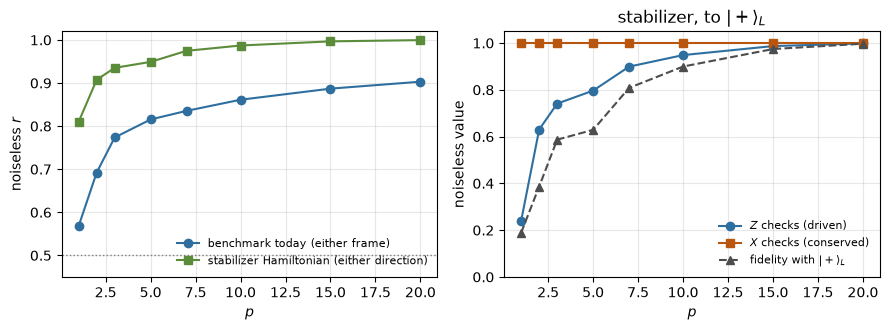

In [8]:
def evolve(variant, depth, delta=DELTA):
    # exact state of the data qubits after the depth-p ramp, and the eight check operators of that variant
    pattern, sign, mixer, _ = VARIANTS[variant]
    ops = [pauli(PX if b == "X" else PZ, {position[d] for d in term.data})
           for term, b in zip(patch.terms, check_bases(patch, pattern))]
    return lrqaoa(ops, sign, mixer, depth, delta), ops


def exact(variant, depth, delta=DELTA):
    psi, ops = evolve(variant, depth, delta)
    return [float(np.real(psi.conj() @ s @ psi)) for s in ops]


def anneal_summary(variant, depth, delta=DELTA):
    # (driven checks, conserved checks, r, fidelity with the logical state, <logical operator>)
    psi, ops = evolve(variant, depth, delta)
    values = [float(np.real(psi.conj() @ s @ psi)) for s in ops]
    kept = VARIANTS[variant][2]                           # the mixer's basis: those checks are conserved
    driven = np.mean([v for v, t in zip(values, code_types) if t != kept])
    conserved = np.mean([v for v, t in zip(values, code_types) if t == kept])
    target = code_space @ (np.eye(2 ** n) + logical[kept]) / 2
    return (driven, conserved, ratio(values, variant), float(np.real(psi.conj() @ target @ psi)),
            float(np.real(psi.conj() @ logical[kept] @ psi)))


ideal = {variant: {p: ratio(exact(variant, p), variant) for p in EXACT_DEPTHS} for variant in VARIANTS}
for variant in ("stabilizer, to |+>_L", "stabilizer, to |0>_L"):
    print(f"\n{variant}")
    print(f"{'p':>3} {'driven checks':>14} {'conserved checks':>17} {'r':>7} {'fidelity':>9} {'<logical>':>10}"
          f" {'r, benchmark today':>20}")
    for p in EXACT_DEPTHS:
        driven, conserved, r, fidelity, lo = anneal_summary(variant, p)
        print(f"{p:>3} {driven:>14.3f} {conserved:>17.3f} {r:>7.3f} {fidelity:>9.3f} {lo:>10.3f}"
              f" {ideal['benchmark, Z frame'][p]:>20.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(EXACT_DEPTHS, [ideal["benchmark, Z frame"][p] for p in EXACT_DEPTHS], "-o", color="#2f6f9f",
             label="benchmark today (either frame)")
axes[0].plot(EXACT_DEPTHS, [ideal["stabilizer, to |+>_L"][p] for p in EXACT_DEPTHS], "-s", color="#5b8c3a",
             label="stabilizer Hamiltonian (either direction)")
axes[0].axhline(0.5, color="0.5", ls=":", lw=1)
axes[0].set(xlabel="$p$", ylabel="noiseless $r$", ylim=(0.45, 1.02))
axes[0].legend(fontsize=8, frameon=False, loc="lower right")
summary = np.array([anneal_summary("stabilizer, to |+>_L", p) for p in EXACT_DEPTHS])
axes[1].plot(EXACT_DEPTHS, summary[:, 0], "-o", color="#2f6f9f", label=r"$Z$ checks (driven)")
axes[1].plot(EXACT_DEPTHS, summary[:, 1], "-s", color="#b8560f", label=r"$X$ checks (conserved)")
axes[1].plot(EXACT_DEPTHS, summary[:, 3], "--^", color="0.3", label=r"fidelity with $|+\rangle_L$")
axes[1].set(xlabel="$p$", ylabel="noiseless value", ylim=(0, 1.05), title=r"stabilizer, to $|+\rangle_L$")
axes[1].legend(fontsize=8, frameon=False, loc="lower right")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### The slope of the ramp

The benchmark uses $\Delta = 0.5$. The stabilizer Hamiltonian has a different spectrum, so the same slope is not
guaranteed to suit it; the table shows it does, and that the useful window is not wide - past $\Delta \approx 1$
the ramp is too coarse and the state never reaches the code.

In [9]:
print(f"stabilizer, to |+>_L: r and fidelity with |+>_L\n")
print(f"{'delta':>6} " + "".join(f"{'p = ' + str(p):>18}" for p in (3, 5, 10)))
for delta in (0.3, 0.5, 0.7, 1.0, 1.5):
    cells = []
    for p in (3, 5, 10):
        _, _, r, fidelity, _ = anneal_summary("stabilizer, to |+>_L", p, delta)
        cells.append(f"{r:.3f} / {fidelity:.3f}")
    print(f"{delta:>6} " + "".join(f"{c:>18}" for c in cells))

stabilizer, to |+>_L: r and fidelity with |+>_L

 delta              p = 3             p = 5            p = 10
   0.3      0.890 / 0.357     0.922 / 0.487     0.954 / 0.667
   0.5      0.935 / 0.587     0.949 / 0.629     0.987 / 0.899
   0.7      0.889 / 0.369     0.955 / 0.761     0.983 / 0.909
   1.0      0.825 / 0.080     0.834 / 0.144     0.852 / 0.145
   1.5      0.786 / 0.095     0.750 / 0.027     0.765 / 0.069


## 6. Measuring the energy: two readouts

A final readout of the data in $Z$ gives the four $Z$ checks and nothing about the $X$ checks; a readout in $X$
gives the other four. The benchmark today needs one readout because all its terms share a basis. The stabilizer
Hamiltonian therefore needs **two circuits per depth**, identical up to a final layer of Hadamards, and its energy
is the sum of the two halves. That is the only extra cost: the CZ count and the number of mid-circuit
measurements per circuit are those of the benchmark (section 4).

An alternative, not explored here, is to end with one ordinary syndrome-extraction round, which reads all eight
stabilizers in a single shot through the ancillas - at the price of one more round of noise, and it would make
the result decodable.

## 7. Gate level: the circuits reproduce the anneal, and how they fare under noise

Two questions for a simulator that runs the real circuits, mid-circuit measurements and feed-forward included:

1. **Do the stabilizer circuits do what section 5 says?** Sampled without noise at $p = 3$ and compared with the
   exact check values. (The two benchmark circuits need no such test: section 4 shows they are the package's own.)
2. **How do the five circuits compare under one noise model?** The model is deliberately simple and uniform -
   depolarizing gates, readout error, and flips and dephasing on the data while the ancillas are measured - so
   the comparison is between circuits, not a prediction for a device.

The simulation runs shot by shot. The stabilizer circuits use Aer's matrix-product-state method, which is fast for
them; the benchmark circuits and the $Y$-mixer circuit entangle too much for it and use the statevector method
with fewer shots.

In [10]:
def simulate():
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error, pauli_error

    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(NOISE["cz"], 2), ["cz"])
    noise.add_all_qubit_quantum_error(depolarizing_error(NOISE["one_qubit"], 1), ["sx", "x", "h", "rx", "ry"])
    xy, z = NOISE["idle_xy"], NOISE["idle_z"]
    noise.add_all_qubit_quantum_error(pauli_error([("X", xy / 2), ("Y", xy / 2), ("Z", z), ("I", 1 - xy - z)]),
                                      ["id"])
    e = NOISE["readout"]
    noise.add_all_qubit_readout_error(ReadoutError([[1 - e, e], [e, 1 - e]]))
    # the ramps that conserve half the checks stay weakly entangled, which the matrix-product-state method exploits
    method = {v: "matrix_product_state" if " to " in v else "statevector" for v in VARIANTS}
    check_shots = {v: 2000 if method[v] == "matrix_product_state" else 1000 for v in VARIANTS if v.startswith("stabilizer")}
    out = {"noise": NOISE, "shots": SHOTS, "depths": SIM_DEPTHS, "check_depth": 3, "check_shots": check_shots,
           "noiseless_check": {}, "noisy": {}}
    for variant in check_shots:
        clean = AerSimulator(method=method[variant])
        values = {}
        for readout in VARIANTS[variant][3]:
            counts = clean.run(transpile(build(patch, 3, variant, readout), clean), shots=check_shots[variant],
                               seed_simulator=1).result().get_counts()
            values.update(check_values(counts, patch, variant, readout))
        out["noiseless_check"][variant] = {"sampled": [values[k] for k in sorted(values)],
                                           "exact": exact(variant, 3)}
    sims = {m: AerSimulator(method=m, noise_model=noise,
                            basis_gates=["cz", "sx", "x", "rz", "h", "rx", "ry", "s", "id"])
            for m in set(method.values())}
    for depth in SIM_DEPTHS:
        for variant in VARIANTS:
            values = {}
            for readout in VARIANTS[variant][3]:
                qc = transpile(build(patch, depth, variant, readout, idle=True), sims[method[variant]],
                               optimization_level=0)
                counts = sims[method[variant]].run(qc, shots=SHOTS[variant],
                                                   seed_simulator=depth).result().get_counts()
                values.update(check_values(counts, patch, variant, readout))
            out["noisy"].setdefault(variant, {})[str(depth)] = [values[k] for k in sorted(values)]
            print(f"   p = {depth}, {variant}: r = {ratio(out['noisy'][variant][str(depth)], variant):.3f}")
    return out


if CACHE.exists() and not RECOMPUTE:
    sim = json.loads(CACHE.read_text())
    print(f"read {CACHE.relative_to(ROOT)}")
else:
    sim = simulate()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    CACHE.write_text(json.dumps(sim, indent=1))
    print(f"written to {CACHE.relative_to(ROOT)}")

print(f"\n1. without noise, p = {sim['check_depth']}: sampled against exact")
for variant, got in sim["noiseless_check"].items():
    worst = max(abs(a - b) for a, b in zip(got["sampled"], got["exact"]))
    print(f"   {variant:>22} ({sim['check_shots'][variant]} shots): r sampled {ratio(got['sampled'], variant):.3f}, "
          f"exact {ratio(got['exact'], variant):.3f}; largest difference in a single check {worst:.3f}")

read data/stabilizer_study/comparison.json

1. without noise, p = 3: sampled against exact
     stabilizer, to |+>_L (2000 shots): r sampled 0.935, exact 0.935; largest difference in a single check 0.012
     stabilizer, to |0>_L (2000 shots): r sampled 0.936, exact 0.935; largest difference in a single check 0.018
      stabilizer, Y mixer (1000 shots): r sampled 0.780, exact 0.774; largest difference in a single check 0.031


### The five circuits under the same noise

$r_{\rm ovl} = (r - \tfrac12)/(r_{\rm ideal} - \tfrac12)$ puts the five on one scale: 1 is the noiseless circuit
and 0 is a state with no stabilizer information left. Error bars are the shot noise.

The right panel splits the stabilizer circuit into its two halves. The **conserved** checks would stay at $+1$
for ever without noise, so their decay is purely the device failing to hold a stabilizer through $p$ rounds of
syndrome-extraction-like gadgets - the part of this benchmark that is closest in kind to the memory experiment.
The **driven** checks carry the algorithm, as the benchmark does today.

2. under noise: r (and r_ovl)

                                 p = 1          p = 2          p = 3          p = 5          p = 7         p = 10
    benchmark, Z frame    0.549 (0.71)   0.671 (0.89)   0.715 (0.79)   0.697 (0.62)   0.690 (0.57)   0.673 (0.48)
    benchmark, X frame    0.561 (0.89)   0.676 (0.92)   0.699 (0.73)   0.693 (0.61)   0.690 (0.57)   0.665 (0.46)
  stabilizer, to |+>_L    0.778 (0.89)   0.845 (0.85)   0.851 (0.81)   0.828 (0.73)   0.806 (0.65)   0.773 (0.56)
  stabilizer, to |0>_L    0.781 (0.90)   0.849 (0.86)   0.853 (0.81)   0.840 (0.76)   0.817 (0.67)   0.791 (0.60)
   stabilizer, Y mixer    0.562 (0.90)   0.667 (0.87)   0.699 (0.73)   0.716 (0.68)   0.689 (0.56)   0.659 (0.44)


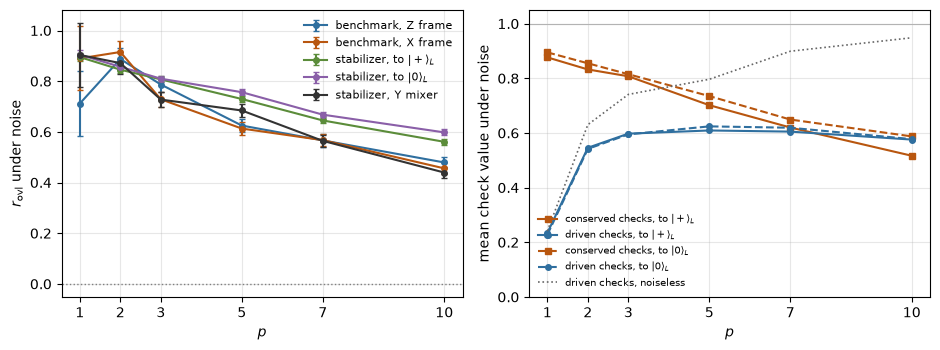


stabilizer circuits under noise: mean check value, conserved / driven (noiseless driven in brackets)
     stabilizer, to |+>_L: p=1: 0.88 / 0.23 [0.24]   p=2: 0.83 / 0.55 [0.63]   p=3: 0.81 / 0.60 [0.74]   p=5: 0.70 / 0.61 [0.80]   p=7: 0.62 / 0.60 [0.90]   p=10: 0.52 / 0.58 [0.95]
     stabilizer, to |0>_L: p=1: 0.90 / 0.23 [0.24]   p=2: 0.85 / 0.54 [0.63]   p=3: 0.81 / 0.59 [0.74]   p=5: 0.73 / 0.62 [0.80]   p=7: 0.65 / 0.62 [0.90]   p=10: 0.59 / 0.58 [0.95]


In [11]:
def shot_error(values, shots):
    # shot noise on r from eight check values, each a +-1 average over `shots`
    return float(np.sqrt(sum(1 - v ** 2 for v in values) / shots) / (2 * len(values)))


depths = sim["depths"]
colour = {"benchmark, Z frame": "#2f6f9f", "benchmark, X frame": "#b8560f",
          "stabilizer, to |+>_L": "#5b8c3a", "stabilizer, to |0>_L": "#8a5fa8", "stabilizer, Y mixer": "0.2"}
table = {}
for variant in VARIANTS:
    rows = []
    for p in depths:
        values = sim["noisy"][variant][str(p)]
        r_ideal = ratio(exact(variant, p), variant)
        r = ratio(values, variant)
        rows.append((r, shot_error(values, sim["shots"][variant]), r_ideal, (r - 0.5) / (r_ideal - 0.5),
                     shot_error(values, sim["shots"][variant]) / (r_ideal - 0.5)))
    table[variant] = np.array(rows)
print("2. under noise: r (and r_ovl)\n")
print(f"{'':>22} " + "".join(f"{'p = ' + str(p):>15}" for p in depths))
for variant in VARIANTS:
    print(f"{variant:>22} " + "".join(f"{row[0]:>8.3f} ({row[3]:.2f})" for row in table[variant]))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for variant in VARIANTS:
    axes[0].errorbar(depths, table[variant][:, 3], yerr=table[variant][:, 4], fmt="-o", ms=4, capsize=2,
                     color=colour[variant], label=variant.replace("|+>_L", r"$|+\rangle_L$").replace("|0>_L", r"$|0\rangle_L$"))
axes[0].axhline(0, color="0.5", ls=":", lw=1)
axes[0].set(xlabel="$p$", ylabel=r"$r_{\rm ovl}$ under noise")
axes[0].legend(fontsize=8, frameon=False)
for variant, style in (("stabilizer, to |+>_L", "-"), ("stabilizer, to |0>_L", "--")):
    kept = VARIANTS[variant][2]
    conserved = [np.mean([v for v, t in zip(sim["noisy"][variant][str(p)], code_types) if t == kept]) for p in depths]
    driven = [np.mean([v for v, t in zip(sim["noisy"][variant][str(p)], code_types) if t != kept]) for p in depths]
    ideal_driven = [anneal_summary(variant, p)[0] for p in depths]
    name = variant.split(", ")[1].replace("|+>_L", r"$|+\rangle_L$").replace("|0>_L", r"$|0\rangle_L$")
    axes[1].plot(depths, conserved, style + "s", color="#b8560f", ms=4, label=f"conserved checks, {name}")
    axes[1].plot(depths, driven, style + "o", color="#2f6f9f", ms=4, label=f"driven checks, {name}")
axes[1].plot(depths, ideal_driven, ":", color="0.4", lw=1.2, label="driven checks, noiseless")
axes[1].axhline(1, color="0.7", lw=0.8)
axes[1].set(xlabel="$p$", ylabel="mean check value under noise", ylim=(0, 1.05))
axes[1].legend(fontsize=7, frameon=False, loc="lower left")
for ax in axes:
    ax.set_xticks(depths)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "stabilizer_hamiltonian_under_noise.pdf", bbox_inches="tight")
plt.show()

print("\nstabilizer circuits under noise: mean check value, conserved / driven (noiseless driven in brackets)")
for variant in ("stabilizer, to |+>_L", "stabilizer, to |0>_L"):
    kept = VARIANTS[variant][2]
    cells = []
    for p in depths:
        values = sim["noisy"][variant][str(p)]
        conserved = np.mean([v for v, t in zip(values, code_types) if t == kept])
        driven = np.mean([v for v, t in zip(values, code_types) if t != kept])
        cells.append(f"{conserved:.2f} / {driven:.2f} [{anneal_summary(variant, p)[0]:.2f}]")
    print(f"   {variant:>22}: " + "   ".join(f"p={p}: {c}" for p, c in zip(depths, cells)))

## 8. What this shows, and what it would take to run it

The numbers below are those of the run stored in `data/stabilizer_study/comparison.json`; the cells above print
their own when the configuration changes.

**It can be built.** The Hamiltonian with the code's own mix of $X$ and $Z$ checks is a valid LR-QAOA problem with
the ordinary mixer. The $Z$-only and $X$-only Hamiltonians give identical results (to $10^{-14}$); the mixed one
does not, despite having the same spectrum, and is exactly the ramp of its four driven checks with the other four
held at $+1$. Its noiseless $r$ therefore starts at $0.81$ and reaches $0.99$ by $p = 10$, where it has prepared
$|+\rangle_L$ (or $|0\rangle_L$) with fidelity $0.90$.

**A $Y$ mixer makes the mixed Hamiltonian the benchmark itself.** $Y_i$ anticommutes with every check that
contains qubit $i$, of either kind, so under $\sum_i Y_i$ from $|{+i}\rangle^{\otimes n}$ all eight checks are driven
and the check values equal those of the $Z$-only benchmark to $10^{-14}$ at every depth. This is the version that
keeps today's benchmark - same $r$, same noiseless reference `ideal_r` - while every layer applies the code's own
pattern of $X$ and $Z$ checks. Under the noise model it also behaves as the benchmark does ($r = 0.70$ at $p = 3$
against $0.71$ and $0.70$ for the two frames).

**The circuit is the package's gadget, unchanged.** One layer applies both kinds of check and reads all eight
ancillas once: 72 CZ gates and 33 measurements at $p = 3$, the same as the benchmark today. Sampled without noise,
the circuits reproduce the exact check values to within shot noise.

**The cost is a second readout.** The $Z$ and the $X$ checks cannot be read from the data in one basis, so each
depth needs two circuits where the benchmark needs one.

**What it adds is a second kind of signal.** Half the checks are conserved by the ideal circuit, so their value on
a device is a direct record of stabilizers being lost: in the simulation they fall from $0.88$-$0.90$ after one
layer to $0.52$-$0.59$ after ten. The two directions separate there, and in the expected sense - the noise model
dephases the idling data more than it flips them, and the direction that conserves the $X$ checks, which only
$Z$-type errors can break, decays faster. That is the asymmetry the two memory experiments measure, obtained here
without a decoder. The driven half behaves as the benchmark does now.

**What the simulation does not show.** The noise model is uniform and simple, so it says nothing about whether
any of these versions ranks real patches better than the two frames do; under it the five circuits lose
$r_{\rm ovl}$ at similar rates, the two that conserve half their checks a little more slowly. Only a device run
can answer that.

**To run it on hardware**, three things would have to be added to the package, none of them here:

1. a third value of `frame` in `qecbench.circuits.build_dynamic` that uses the code's check types, as `build`
   above does;
2. a second readout basis per circuit in the plan, and an analysis that adds the two halves of the energy;
3. a noiseless reference: for the $Y$-mixer version it is `ideal_r` itself, unchanged, at any distance; for the
   two versions that conserve half the checks, section 5 computes it for $d = 3$, and by the first test it
   reduces at $d = 5$ to the ramp of the driven checks alone.

Of the three, the $Y$-mixer version is the smallest step: one more value of `frame`, an `ry` mixer, and a second
readout basis, with every reference and every figure of merit of the benchmark carrying over as they are.